# El factor de roca: de dónde sale el único número libre de la ecuación clásica

**Pregunta:** ¿Cuánto varía el factor de roca dentro de un sitio y entre sitios?

**Nivel 2: El método en la práctica** · Requiere: 02-classical-prediction/01-the-classical-equation-on-one-blast · Tiempo de lectura: unos 30 minutos

## Objetivos

Ambos artículos fuente dicen que el factor de roca `A` "se estimó para cada tiro", y ninguno imprime un valor. Sin él la ecuación clásica no puede ejecutarse. Este notebook pregunta cuánto varía ese único número libre, dentro de un sitio y entre sitios, y prueba las dos maneras en que el motor puede obtenerlo: invirtiendo la ecuación sobre una predicción publicada, y desde una tabla de clasificación publicada.

Al terminar, usted habrá:

- recuperado un factor de roca para cada tiro de validación con predicción clásica impresa, paso a paso con el motor, y agrupado los resultados por sitio;
- medido la dispersión del factor dentro de un sitio (que pone a prueba la reconstrucción de la geometría) y entre sitios (que es la roca);
- mostrado que la derivación del propio motor es igual a la tabla de factores que fija;
- comparado los factores recuperados de las columnas de los dos artículos, y ejecutado los tres esquemas de clasificación publicados sobre el único sitio cuya roca describe el corpus.

## Preparación

Instale los paquetes con las versiones exactas de `notebooks/requirements.txt`. El motor es `blastfrag`, publicado en PyPI; los otros paquetes son su base numérica y la biblioteca de gráficos.

```bash
pip install blastfrag==0.4.0 numpy==2.5.4 matplotlib==3.11.2
```

La celda de preparación siguiente importa los paquetes, imprime sus versiones instaladas para que la salida registre qué motor produjo cada número, fija la ruta a los artefactos versionados y el estilo de los gráficos, y define `show_table`, un ayudante de cuatro líneas que dibuja filas como tabla Markdown porque el entorno de notebooks no tiene `pandas`.

In [1]:
# Importaciones, versiones fijadas, ruta de datos, estilo de gráficos y un ayudante de tablas
import itertools
import json
import re
from importlib.metadata import version
from pathlib import Path

import blastfrag as bf
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display

for name in ("blastfrag", "numpy", "matplotlib"):
    print(f"{name}=={version(name)}")

DERIVED = Path("../../../data/derived")
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})


def show_table(header, rows, left=1):
    # Dibujar las filas como tabla Markdown, las primeras `left` columnas a la izquierda y las demás a la derecha
    lines = ["| " + " | ".join(header) + " |", "|" + ":---|" * left + "---:|" * (len(header) - left)]
    lines += ["| " + " | ".join(str(cell) for cell in row) + " |" for row in rows]
    text = "\n".join(lines)
    display({"text/markdown": text, "text/plain": text}, raw=True)

blastfrag==0.4.0
numpy==2.5.4
matplotlib==3.11.2


## Datos

| Fuente | Titular y URL | Clase de licencia | Archivo que lee el notebook |
|---|---|---|---|
| Los tiros de validación con la columna clásica que imprime cada artículo | Hudaverdi, Kulatilake y Kuzu 2010, https://doi.org/10.1002/nag.957; Kulatilake, Hudaverdi y Wu 2012, https://doi.org/10.1007/s10706-012-9496-3 | hechos numéricos reutilizados con cita; los artículos nunca se distribuyen | `bf.load_holdout()` dentro del paquete `blastfrag` |
| La descripción de la roca de cada sitio (resistencia, densidad, módulo) | los mismos artículos, tal como los lleva el benchmark versionado | hechos numéricos reutilizados con cita | `data/derived/benchmark.json`, campo `site_meta` |
| Las tablas de clasificación | Hudaverdi et al. 2010 Ecs. 2 y 3; Babaeian et al. 2019, https://doi.org/10.1016/j.jrmge.2018.11.006 (Tablas 1 y 2) | las tablas se reproducen con cita | `bf.rock_factor` y `bf.SCHEMES` en el motor |

## Método

**Ruta 1, una tabla de clasificación.** El índice de tronabilidad de Lilly es la suma de cinco valoraciones (descripción del macizo, espaciamiento de juntas, orientación del plano de juntas, un término de densidad y uno de resistencia), y el factor de roca es 0,06 veces el índice (Hudaverdi, Kulatilake y Kuzu 2010, https://doi.org/10.1002/nag.957, Ecs. 2 y 3). Babaeian et al. 2019 (https://doi.org/10.1016/j.jrmge.2018.11.006) imprimen la misma suma con un término de resistencia distinto y otras tablas de valoración, y tabulan una tercera, una consulta de cinco bandas de Hustrulid.

**Ruta 2, inversión.** La ecuación del notebook anterior es lineal en `A`, así que una predicción publicada `x50_pub` para un tiro con `V` y `Q` conocidos lo fija:

```
A = x50_pub / [ (V / Q)^0.8 * Q^(1/6) * (RWS / 115)^(-19/30) ]
```

El valor recuperado solo merece confianza si es casi el mismo para todos los tiros de un sitio, porque la roca no cambia dentro de una campaña. Esa constancia es además una prueba de la reconstrucción de la geometría: un error en el bordo o en la altura de banco dispersaría el factor.

### Paso 1: las columnas publicadas

El motor trae los dos conjuntos de validación publicados como una unión de 14 tiros y, para cada tiro, las predicciones que imprimió cada artículo. La celda carga la unión y lista, por sitio, cuántos tiros de validación tiene, cuántos de ellos tienen escala conocida (la inversión necesita `V` y `Q`) y cuántos llevan un tamaño clásico impreso de 2012, la columna que fija el motor. También se carga aquí el corpus de entrenamiento, pues un paso posterior lo necesita.

In [2]:
# La unión de los dos conjuntos de validación publicados: tiros por sitio y cuáles traen una predicción clásica impresa
train = bf.load_training_corpus()
holdout = bf.load_holdout(protocol="union")
rows = []
for site in sorted({b.site for b in holdout}):
    members = [b for b in holdout if b.site == site]
    scaled = sum(bf.has_absolute_geometry(b) for b in members)
    printed = sum(b.meta["published"].get("kuzram_2012") is not None for b in members)
    rows.append((site, len(members), scaled, printed))
header = ["sitio", "tiros de validación", "con escala conocida",
          "con tamaño clásico impreso de 2012"]
show_table(header, rows)
print("columnas impresas de cada tiro:", sorted(holdout[0].meta["published"]))

| sitio | tiros de validación | con escala conocida | con tamaño clásico impreso de 2012 |
|:---|---:|---:|---:|
| Akdaglar | 3 | 3 | 2 |
| Dongri-Buzurg | 1 | 1 | 1 |
| Enusa | 1 | 1 | 1 |
| Miami | 1 | 0 | 0 |
| Mrica | 1 | 1 | 1 |
| Murgul | 2 | 2 | 2 |
| Ozmert | 2 | 2 | 2 |
| Reocin | 1 | 1 | 1 |
| Reocin-UG | 1 | 1 | 1 |
| Soma | 1 | 1 | 1 |

columnas impresas de cada tiro: ['kuzram_2010', 'kuzram_2012', 'nn_mean_2012', 'regression_2010', 'regression_2012']


Doce de los 14 tiros de validación se pueden invertir: el único tiro de Miami no tiene escala, y un tiro de Akdaglar no tiene tamaño impreso de 2012. Seis sitios tienen un solo tiro utilizable y tres (Akdaglar, Murgul, Ozmert) tienen dos, así que la evidencia sobre la dispersión dentro de un sitio descansará en tres pares. Las cinco columnas impresas son dos predicciones clásicas (2010 y 2012), dos regresiones y una red; solo las clásicas conciernen a este notebook. La tabla cuenta tiros; todavía no dice nada del factor.

### Paso 2: invertir la ecuación en cada tiro

Para cada tiro utilizable la celda reconstruye el patrón, toma su volumen de roca `V` y su masa de explosivo `Q`, y llama a `back_solve_rock_factor` con el tamaño impreso de 2012. El resultado es un factor de roca por tiro. La tabla lista cada tiro con los números que produjeron su factor, de modo que cada intermedio es visible.

In [3]:
# Invertir la ecuación en cada tiro de validación con escala y con tamaño clásico impreso de 2012
per_blast = []
for blast in holdout:
    published = blast.meta["published"].get("kuzram_2012")
    if published is None or not bf.has_absolute_geometry(blast):
        continue
    pattern = bf.reconstruct_pattern(blast)
    volume, mass = pattern.rock_volume_m3, pattern.charge_mass_kg
    factor = bf.back_solve_rock_factor(published, rock_volume_m3=volume, charge_mass_kg=mass)
    per_blast.append((blast.blast_id, blast.site, published, volume, mass, factor))
rows = [(i, s, f"{x:.2f}", f"{v:.1f}", f"{q:.1f}", f"{a:.3f}") for i, s, x, v, q, a in per_blast]
header = ["tiro", "sitio", "x50 impreso (m)", "V (m3)", "Q (kg)", "A recuperado"]
show_table(header, rows, left=2)

| tiro | sitio | x50 impreso (m) | V (m3) | Q (kg) | A recuperado |
|:---|:---|---:|---:|---:|---:|
| En13 | Enusa | 0.44 | 150.2 | 72.1 | 10.973 |
| Ru7 | Reocin-UG | 0.65 | 263.5 | 81.7 | 11.191 |
| Mg8 | Murgul | 0.39 | 329.9 | 181.4 | 9.299 |
| Mg9 | Murgul | 0.30 | 243.2 | 182.4 | 9.160 |
| Rc1 | Reocin | 0.72 | 379.0 | 125.1 | 12.139 |
| Mr12 | Mrica | 0.24 | 108.0 | 51.8 | 6.324 |
| Db10 | Dongri-Buzurg | 0.08 | 40.0 | 35.6 | 3.677 |
| Sm8 | Soma | 0.35 | 674.9 | 283.5 | 6.244 |
| Oz8 | Ozmert | 0.20 | 45.0 | 23.9 | 6.493 |
| Oz9 | Ozmert | 0.23 | 72.8 | 34.2 | 6.387 |
| Ad23 | Akdaglar | 0.11 | 23.6 | 29.6 | 6.845 |
| Ad24 | Akdaglar | 0.13 | 22.2 | 19.7 | 6.594 |

Los doce factores van de 3,677 (Db10, Dongri-Buzurg, un tiro de 40 m3 con 0,08 m impreso) a 12,139 (Rc1, Reocin, un tiro de 379 m3 con 0,72 m impreso). Los dos tiros de Murgul dan 9,299 y 9,160, los dos de Ozmert 6,493 y 6,387, los dos de Akdaglar 6,845 y 6,594: cercanos en pares, lejanos entre sitios. La tabla muestra los factores tiro a tiro; si la cercanía dentro de los pares es real o redondeo es una pregunta para la figura del paso siguiente.

### Paso 3: dentro de un sitio y entre sitios

La celda agrupa los factores por sitio y dibuja dos paneles. El izquierdo ubica el factor de cada tiro como un punto azul en una fila por sitio, con la media del sitio como una marca naranja. El derecho compara la dispersión dentro de cada sitio que tiene dos tiros, medida como máximo menos mínimo sobre la media, con la misma medida aplicada a las nueve medias de sitio. Si el factor es una propiedad de la roca, las barras azules deben ser diminutas y la naranja grande.

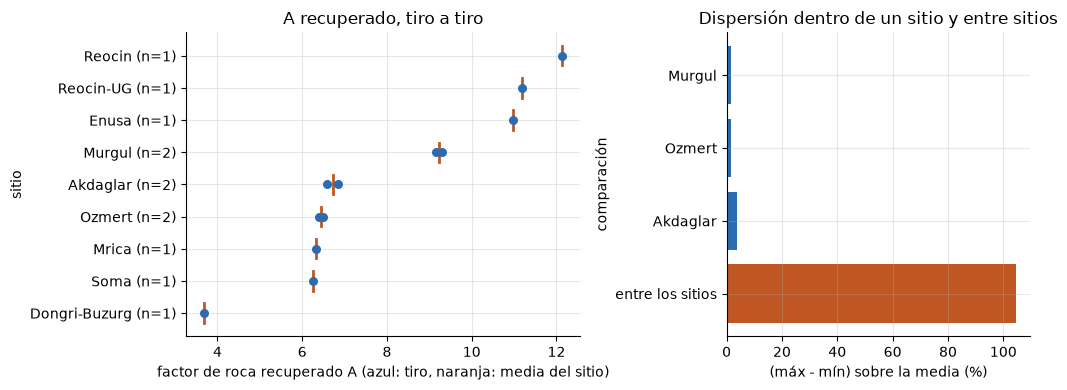

mayor dispersión dentro de un sitio (%): 3.7
dispersión entre las medias de sitio (%): 104
media de sitio mayor sobre la menor: 3.3


In [4]:
# Agrupar los factores recuperados por sitio: la media, la dispersión dentro del sitio y el rango entre sitios
by_site = {}
for _, site, _, _, _, factor in per_blast:
    by_site.setdefault(site, []).append(factor)
means = {site: float(np.mean(values)) for site, values in by_site.items()}
spread = {site: (max(v) - min(v)) / np.mean(v) * 100 for site, v in by_site.items() if len(v) > 1}
between = (max(means.values()) - min(means.values())) / np.mean(list(means.values())) * 100
order = sorted(means, key=means.get)
fig, (left, right) = plt.subplots(1, 2, figsize=(10.5, 4), gridspec_kw={"width_ratios": [1.3, 1]})
for position, site in enumerate(order):
    left.scatter(by_site[site], [position] * len(by_site[site]), s=30, color="#2b6cb0", zorder=3)
    left.plot([means[site]] * 2, [position - 0.3, position + 0.3], color="#c05621", lw=2)
left.set_yticks(range(len(order)), [f"{site} (n={len(by_site[site])})" for site in order])
left.set_xlabel("factor de roca recuperado A (azul: tiro, naranja: media del sitio)")
left.set_ylabel("sitio")
left.set_title("A recuperado, tiro a tiro")
labels = [*spread, "entre los sitios"]
right.barh(range(len(labels)), [*spread.values(), between], color=["#2b6cb0"] * len(spread) + ["#c05621"])
right.set_yticks(range(len(labels)), labels)
right.invert_yaxis()
right.set_xlabel("(máx - mín) sobre la media (%)")
right.set_ylabel("comparación")
right.set_title("Dispersión dentro de un sitio y entre sitios")
fig.tight_layout()
plt.show()
print("mayor dispersión dentro de un sitio (%):", f"{max(spread.values()):.1f}")
print("dispersión entre las medias de sitio (%):", f"{between:.0f}")
print("media de sitio mayor sobre la menor:", f"{max(means.values()) / min(means.values()):.1f}")

Los dos tiros de un sitio casi coinciden, y los sitios no: la mayor dispersión dentro de un sitio es 3,7 por ciento, en Akdaglar, mientras que la dispersión entre las nueve medias de sitio es 104 por ciento de su media, y la mayor media de sitio es 3,3 veces la menor. Un 0,11 m impreso representa cualquier valor de 0,105 a 0,115 m, una dispersión de 9 por ciento en sí misma, así que unos pocos por ciento de dispersión dentro de un sitio es lo que produce redondear las predicciones impresas a dos decimales, y no es señal de una geometría errónea. La figura muestra que el factor se comporta como una constante del sitio. Descansa en solo tres pares de tiros, así que respalda la reconstrucción sin demostrarla.

### Paso 4: la derivación del motor y la tabla que fija

El motor hace la misma agrupación en una llamada, `derive_site_rock_factors`, y distribuye el resultado como la tabla fijada `SITE_ROCK_FACTOR`, los factores que usa todo predictor clásico. La celda compara dos cosas: la derivación del motor redondeada a dos decimales contra la tabla fijada, y las medias del paso anterior contra la derivación del motor. Esta es la única verificación de reproducción del notebook, y cierra el ciclo: los factores que usa el producto son los derivados aquí, paso a paso.

In [5]:
# La derivación del propio motor, redondeada a dos decimales, contra la tabla que fija y contra las medias anteriores
derived = bf.derive_site_rock_factors("kuzram_2012")
same_table = all(round(mean, 2) == bf.SITE_ROCK_FACTOR[site] for site, (mean, _, _) in derived.items())
same_means = np.allclose([derived[s][0] for s in means], [means[s] for s in means], rtol=0, atol=1e-9)
print("factores derivados iguales a la tabla fijada:", same_table, "| sitios:", len(derived))
print("medias paso a paso iguales a la derivación del motor:", same_means)

factores derivados iguales a la tabla fijada: True | sitios: 9
medias paso a paso iguales a la derivación del motor: True


Ambas comparaciones se cumplen en los nueve sitios: los factores derivados, redondeados a dos decimales, son iguales a la tabla fijada, y las medias calculadas paso a paso son iguales a la derivación del motor a 1e-9. Así que los números de los pasos anteriores son los números que usa el producto, sin ajuste oculto. La verificación no dice si esos números son correctos: se derivan de predicciones impresas, y los pasos siguientes miran las propias predicciones impresas.

### Paso 5: las dos columnas impresas discrepan

El artículo de 2010 imprimió tamaños clásicos mayores que el de 2012 para los mismos tiros. Invertir cada columna da un factor distinto por sitio, porque el factor es lo que hace que la ecuación reproduzca la columna. `derive_site_rock_factors` recibe la columna como argumento; la celda deriva ambos y tabula los factores y su razón. Mezclar columnas sería un defecto, así que el motor fija una.

In [6]:
# El factor recuperado de la columna impresa de cada artículo, sitio a sitio, y la razón entre ambos
f2012 = bf.derive_site_rock_factors("kuzram_2012")
f2010 = bf.derive_site_rock_factors("kuzram_2010")
sites = sorted(f2010)
ratios = {site: f2010[site][0] / f2012[site][0] for site in sites}
rows = [(site, f"{f2012[site][0]:.2f}", f"{f2010[site][0]:.2f}", f"{ratios[site]:.3f}") for site in sites]
show_table(["sitio", "A (2012)", "A (2010)", "2010 / 2012"], rows)
values = list(ratios.values())
print(f"razón media: {np.mean(values):.3f} | rango: {min(values):.3f} a {max(values):.3f}")

| sitio | A (2012) | A (2010) | 2010 / 2012 |
|:---|---:|---:|---:|
| Akdaglar | 6.72 | 7.03 | 1.045 |
| Dongri-Buzurg | 3.68 | 4.14 | 1.125 |
| Enusa | 10.97 | 11.97 | 1.091 |
| Mrica | 6.32 | 7.11 | 1.125 |
| Murgul | 9.23 | 10.05 | 1.088 |
| Ozmert | 6.44 | 7.04 | 1.094 |
| Reocin-UG | 11.19 | 12.22 | 1.092 |
| Soma | 6.24 | 6.78 | 1.086 |

razón media: 1.093 | rango: 1.045 a 1.125


La columna de 2010 implica factores mayores en cada uno de los ocho sitios que cubre, de 1,045 a 1,125 veces, 1,093 en promedio (Reocin no tiene tamaño impreso de 2010). La razón no es constante, así que los dos artículos no difirieron en un solo escalamiento: imprimieron números distintos para los mismos tiros. El factor es entonces una propiedad del par (sitio, columna impresa) y no solo de la roca, por lo que el motor fija la columna de 2012, la que además lleva los otros dos predictores publicados, y nunca mezcla las dos.

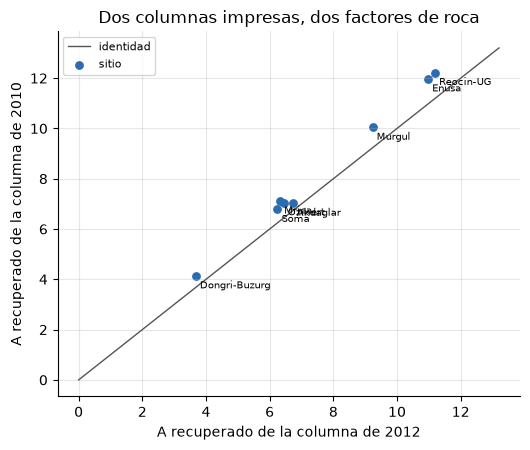

In [7]:
# Factor recuperado de la columna de 2010 contra la de 2012, un punto por sitio, con la línea de identidad
x = np.array([f2012[s][0] for s in sites])
y = np.array([f2010[s][0] for s in sites])
fig, ax = plt.subplots(figsize=(5.4, 4.6))
limit = max(x.max(), y.max()) * 1.08
ax.plot([0, limit], [0, limit], color="#555", lw=1, label="identidad")
ax.scatter(x, y, s=28, color="#2b6cb0", label="sitio")
for site, xi, yi in zip(sites, x, y):
    ax.annotate(site, (xi, yi), fontsize=7, xytext=(3, -9), textcoords="offset points")
ax.set_xlabel("A recuperado de la columna de 2012")
ax.set_ylabel("A recuperado de la columna de 2010")
ax.set_title("Dos columnas impresas, dos factores de roca")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

Cada punto es un sitio: el factor recuperado de la columna de 2012 en el eje horizontal y de la de 2010 en el vertical, con la línea de identidad como referencia. Los ocho puntos quedan por encima de la línea, ninguno lejos de ella, y el orden de los sitios es casi el mismo en las dos columnas, así que los dos artículos coinciden en qué roca es dura y cuál es blanda. La figura muestra un desfase entre las columnas, no un desacuerdo sobre el orden; no dice cuál columna es más exacta, y nada en el corpus puede hacerlo.

### Paso 6: qué da una tabla de clasificación para la misma roca

Los esquemas de clasificación necesitan una descripción de la roca. El corpus describe solo la de Akdaglar, en el benchmark versionado (una arenisca, con su resistencia, densidad y módulo). La primera celda convierte esa descripción en números y toma el bloque in situ medio del sitio, que este notebook usa como espaciamiento de juntas, un supuesto y no un dato. La segunda celda ejecuta cada esquema sobre cada categoría de macizo y de orientación de juntas que reconoce, ya que el corpus no registra esas dos, y guarda el factor mínimo y máximo que puede producir cada esquema.

In [8]:
# La descripción de la roca de Akdaglar, convertida en los números que piden las tablas
benchmark = json.loads((DERIVED / "benchmark.json").read_text(encoding="utf-8"))
text = benchmark["site_meta"]["Akdaglar"]["rock"]
patterns = {"ucs": r"UCS ([\d.]+) MPa", "density": r"density ([\d.]+) g/cm3", "modulus": r"E ([\d.]+) GPa"}
found = {name: float(re.search(pattern, text)[1]) for name, pattern in patterns.items()}
ucs, density, modulus = found["ucs"], found["density"], found["modulus"]
block = float(np.mean([b.XB_m for b in train if b.site == "Akdaglar"]))
print("descripción de la roca:", text)
print(f"bloque in situ medio (m), usado como espaciamiento de juntas: {block:.3f}")

descripción de la roca: sandstone, density 2.70 g/cm3, UCS 81 MPa, E 16.9 GPa
bloque in situ medio (m), usado como espaciamiento de juntas: 1.185


Akdaglar es una arenisca de 2,70 g/cm3, con una resistencia de 81 MPa y un módulo de 16,9 GPa, y su bloque in situ medio es de 1,185 m. Los esquemas de clasificación necesitan además una descripción del macizo y una orientación del plano de juntas que el corpus no trae, así que la celda siguiente prueba cada categoría que reconocen las tablas.

In [9]:
# Ejecutar cada esquema de clasificación sobre cada categoría de macizo y de juntas que reconoce, y guardar los extremos
masses = ("powdery", "blocky", "vertically_jointed", "massive")
orientations = ("horizontal", "dip_out_of_face", "strike_normal_to_face", "dip_into_face")
ranges = {}
for scheme in bf.SCHEMES:
    values = []
    for mass, orientation in itertools.product(masses, orientations):
        rock = bf.Rock(E_GPa=modulus, in_situ_block_m=block, ucs_mpa=ucs, density_t_m3=density,
                       rock_mass_description=mass, joint_spacing_m=block, joint_plane_orientation=orientation)
        try:
            values.append(bf.rock_factor(rock, scheme=scheme))
        except bf.rockfactor.RockFactorUnavailable:
            continue  # una categoría para la que este esquema no tiene valoración
    ranges[scheme] = (min(values), max(values), len(values))
rows = [(scheme, f"{low:.2f}", f"{high:.2f}", f"{high / low:.2f}", n) for scheme, (low, high, n) in ranges.items()]
header = ["esquema", "A mínimo", "A máximo", "máximo sobre mínimo",
          "categorías valoradas"]
show_table(header, rows)
print("recuperado por inversión en Akdaglar:", bf.SITE_ROCK_FACTOR["Akdaglar"])

| esquema | A mínimo | A máximo | máximo sobre mínimo | categorías valoradas |
|:---|---:|---:|---:|---:|
| lilly-hudaverdi | 2.75 | 4.85 | 1.76 | 12 |
| lilly-babaeian | 3.44 | 5.54 | 1.61 | 12 |
| hustrulid | 7.00 | 7.00 | 1.00 | 16 |

recuperado por inversión en Akdaglar: 6.72


El esquema de Lilly de Hudaverdi et al. abarca de 2,75 a 4,85 en sus 12 categorías, y la variante de Babaeian et al. abarca de 3,44 a 5,54 en 12; ambas bandas quedan bajo el 6,72 recuperado por inversión. La consulta de Hustrulid devuelve 7,00 para las 16 combinaciones, porque ignora las dos categorías, y queda cerca del valor recuperado. Así que las tablas discrepan entre sí tanto como discrepan de los datos, y el ancho de cada banda de Lilly, un factor de aproximadamente 1,8 y 1,6, es el precio de dos categorías que nadie registró.

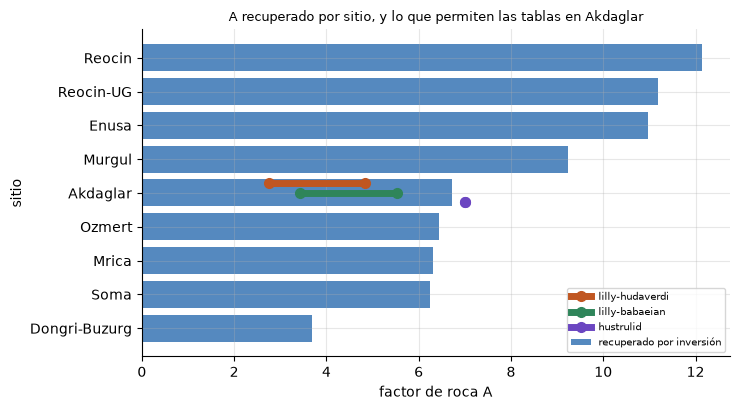

In [10]:
# El factor recuperado de cada sitio como barras, con el rango de cada esquema dibujado sobre Akdaglar
order = sorted(bf.SITE_ROCK_FACTOR, key=bf.SITE_ROCK_FACTOR.get)
fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.barh(order, [bf.SITE_ROCK_FACTOR[s] for s in order], color="#2b6cb0", alpha=0.8, label="recuperado por inversión")
row = order.index("Akdaglar")
colors = {"lilly-hudaverdi": "#c05621", "lilly-babaeian": "#2f855a", "hustrulid": "#6b46c1"}
for offset, (scheme, (low, high, _)) in zip((0.28, 0.0, -0.28), ranges.items()):
    ax.plot([low, high], [row + offset] * 2, color=colors[scheme], lw=5, marker="o", ms=7, label=scheme)
ax.set_xlabel("factor de roca A")
ax.set_ylabel("sitio")
ax.set_title("A recuperado por sitio, y lo que permiten las tablas en Akdaglar", fontsize=9)
ax.legend(fontsize=7, loc="lower right")
fig.tight_layout()
plt.show()

Las barras azules son los factores recuperados en cada sitio, ordenados; los tres segmentos de color sobre la barra de Akdaglar son los rangos que pueden producir los esquemas de clasificación para su roca. Los dos segmentos de Lilly terminan antes del fin de la barra, y el punto de Hustrulid queda un poco más allá. La figura muestra que ninguna tabla fija el factor con este corpus: los dos esquemas que dependen de categorías dan una banda ancha que no alcanza el objetivo, y el que no depende de ellas da un solo número. Descansa en un solo sitio y en un espaciamiento de juntas supuesto, así que es una muestra del problema, no un veredicto sobre las tablas.

## Resultados

**Respuesta:** Dentro de un sitio el factor de roca recuperado varía a lo más 3,7 por ciento, que es lo que produce el redondeo de las predicciones impresas, mientras que entre los nueve sitios el factor varía 104 por ciento de su media y la mayor media de sitio es 3,3 veces la menor. El factor se comporta como una constante del sitio, y la roca, no la aritmética, lleva la variación. La derivación del motor es igual a la tabla de factores que fija en los nueve sitios. Las dos columnas impresas dan factores que difieren de 1,045 a 1,125 veces, y las tablas de clasificación no fijan el factor: en Akdaglar los dos esquemas de Lilly abarcan de 2,75 a 4,85 y de 3,44 a 5,54, frente a un 6,72 recuperado, mientras la consulta de Hustrulid devuelve 7,00.

**Qué se sigue.** El predictor clásico de los notebooks siguientes usa estas nueve constantes, y cada una vale lo que vale la columna impresa de la que se recuperó. Un sitio sin predicción impresa, o una mina nueva, no tiene factor alguno a menos que algo lo prediga, que es la pregunta del último notebook de este tema.

**Lo que este notebook no muestra.** Los factores recuperados provienen de las predicciones publicadas de los mismos tiros que contienen los conjuntos de validación, así que el predictor clásico que los usa lleva conocimiento del sitio sobre el que se puntúa. La evidencia dentro de un sitio descansa en tres pares de tiros. La comparación con las tablas usa un sitio y un espaciamiento de juntas supuesto. Ninguna de las rutas dice qué factor es físicamente correcto.

## Resumen

- La ecuación clásica es lineal en el factor de roca, así que una predicción impresa lo fija, y `back_solve_rock_factor` recupera un factor por tiro.
- Dentro de un sitio el factor varía a lo más 3,7 por ciento y entre los nueve sitios 104 por ciento de la media (mayor sobre menor, 3,3), así que se comporta como una constante del sitio.
- `derive_site_rock_factors` del motor es igual a la tabla `SITE_ROCK_FACTOR` que fija en los nueve sitios.
- Las columnas de 2010 y 2012 implican factores separados por 1,045 a 1,125 veces, y el motor fija la columna de 2012.
- Las tablas de clasificación no pueden fijar el factor con este corpus: en Akdaglar los esquemas de Lilly dan de 2,75 a 4,85 y de 3,44 a 5,54 frente a 6,72 recuperado.
- Siguiente: el notebook 03 puntúa los predictores publicados en sus propias tablas de validación (nivel 3).

## Referencias

- Hudaverdi, Kulatilake y Kuzu 2010, https://doi.org/10.1002/nag.957 (Ecs. 1 a 3, la columna clásica de 2010)
- Kulatilake, Hudaverdi y Wu 2012, https://doi.org/10.1007/s10706-012-9496-3 (el conjunto de validación de 2012 y su columna clásica)
- Babaeian et al. 2019, https://doi.org/10.1016/j.jrmge.2018.11.006 (Tablas 1 y 2, la segunda tabla de clasificación y la consulta de Hustrulid)
- `blastfrag` 0.4.0, el motor, en PyPI: https://pypi.org/project/blastfrag/